# MOKE Analysis: Domains

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FILE = "IP_20x_1-19_hysteresis.csv"   # path to your MOKE data file
SAMPLE_LABEL = "Fe/Si substrate"                # title shown on the plot
LEGEND_LABEL = r"$\perp$ to Field"    # legend text

## 1. Load data and extract the required columns

In [2]:
df = pd.read_csv(FILE)
df.columns = df.columns.str.strip()

print(df.shape)
display(df.head())

# Field1_G is in Gauss; in CGS units 1 G = 1 Oe, so it is used directly as Field (Oe)
field = df["Field1_G"].to_numpy(dtype=float)
brightness = df["AdjROI_0"].to_numpy(dtype=float)

# Drop any rows with missing values
mask = np.isfinite(field) & np.isfinite(brightness)
field, brightness = field[mask], brightness[mask]

print(f"Field range: {field.min():.1f} to {field.max():.1f} Oe")
print(f"AdjROI_0 range: {brightness.min():.4f} to {brightness.max():.4f}")

(262, 9)


,Image_name,Time_taken,Coil_1_mA,Coil_2_mA,Field1_G,Field2_G,ROI_0,AdjROI_0,BkGnd
0,1,17:46:57:720,-200,0,-144.670169,0.035,326.739036,326.739036,326.739036
1,2,17:46:57:871,-195,0,-140.960678,0.035,326.741320,326.741320,326.741320
2,3,17:46:58:011,-190,0,-137.251186,0.035,326.760102,326.760102,326.760102
3,4,17:46:58:151,-185,0,-133.541695,0.035,326.756506,326.756506,326.756506
4,5,17:46:58:266,-180,0,-129.832203,0.035,326.764152,326.764152,326.764152


Field range: -148.4 to 148.4 Oe
AdjROI_0 range: 326.7390 to 327.8006


## 2. Plot Brightness vs Field

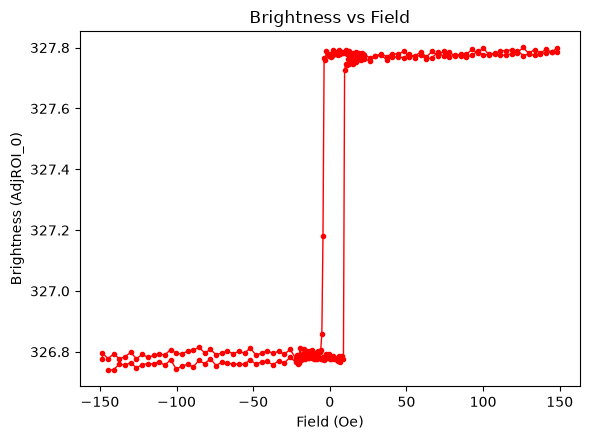

In [3]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(field, brightness, "-o", color="red", ms=3, lw=1)
ax.set_xlabel("Field (Oe)")
ax.set_ylabel("Brightness (AdjROI_0)")
ax.set_title("Brightness vs Field")
plt.tight_layout()
plt.show()

## 3. Normalise AdjROI_0 from -1 to 1

Linear rescaling so the minimum maps to -1 and the maximum to +1:

$$M/M_s = 2\,\frac{I - I_{min}}{I_{max} - I_{min}} - 1$$

In [4]:
imin, imax = brightness.min(), brightness.max()
m_norm = 2 * (brightness - imin) / (imax - imin) - 1

print(f"Normalised range: {m_norm.min():.2f} to {m_norm.max():.2f}")

Normalised range: -1.00 to 1.00


## 4. Plot normalised Magnetisation vs Field

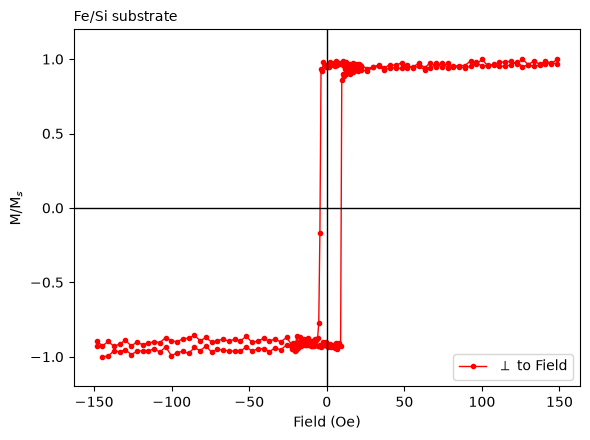

In [5]:
fig, ax = plt.subplots(figsize=(6, 4.5))

ax.plot(field, m_norm, "-o", color="red", ms=3, lw=1, label=LEGEND_LABEL)

# Axes crossing at the origin, as in the reference plot
ax.axhline(0, color="k", lw=1)
ax.axvline(0, color="k", lw=1)

pad = 0.05 * (field.max() - field.min())
ax.set_xlim(field.min() - pad, field.max() + pad)
ax.set_ylim(-1.2, 1.2)
ax.set_yticks([-1.0, -0.5, 0.0, 0.5, 1.0])

ax.set_xlabel("Field (Oe)")
ax.set_ylabel(r"M/M$_s$")
ax.set_title(SAMPLE_LABEL, loc="left", fontsize=10)
ax.legend(loc="lower right", frameon=True)

plt.tight_layout()
plt.savefig("MOKE_hysteresis.png", dpi=300)
plt.show()

### Coercive field
Field values where the normalised loop crosses M = 0 on the up and down sweeps.

In [6]:
# Indices where M changes sign between consecutive points
idx = np.where(np.diff(np.sign(m_norm)) != 0)[0]

crossings = []
for i in idx:
    # linear interpolation for the field at M = 0
    h = field[i] - m_norm[i] * (field[i + 1] - field[i]) / (m_norm[i + 1] - m_norm[i])
    crossings.append(h)

print("Zero crossings of M at H (Oe):", np.round(crossings, 2))
if len(crossings) >= 2:
    print(f"Coercive field Hc ~ {abs(crossings[0] - crossings[-1]) / 2:.2f} Oe")

Zero crossings of M at H (Oe): [ 9.29 -4.34]
Coercive field Hc ~ 6.81 Oe
